# Metadata

In [1]:
# load metadata
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().parent.parent
filepath = ROOT / "data" / "brset" / "metadata.csv"

df = pd.read_csv(filepath)
df

,image_id,patient_id,camera,patient_age,comorbidities,diabetes_time_y,insuline,patient_sex,exam_eye,diabetes,...,amd,vascular_occlusion,hypertensive_retinopathy,drusens,hemorrhage,retinal_detachment,myopic_fundus,increased_cup_disc,other,quality
0,img00001,1,Canon CR,48.0,diabetes1,12,yes,1,1,yes,...,0,0,0,0,0,0,0,1,0,Adequate
1,img00002,1,Canon CR,48.0,diabetes1,12,yes,1,2,yes,...,0,0,0,0,0,0,0,1,0,Adequate
2,img00003,2,Canon CR,18.0,diabetes1,7,yes,2,1,yes,...,0,0,0,0,0,0,0,0,0,Adequate
3,img00004,2,Canon CR,18.0,diabetes1,7,yes,2,2,yes,...,0,0,0,0,0,0,0,0,0,Adequate
4,img00005,3,Canon CR,22.0,diabetes1,11,yes,1,1,yes,...,0,0,0,0,0,0,0,0,0,Adequate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16261,img16262,8522,Canon CR,33.0,diabetes1,14,yes,1,2,yes,...,0,0,0,0,0,0,0,1,0,Adequate
16262,img16263,8523,Canon CR,19.0,diabetes1,4,yes,1,1,yes,...,0,0,0,0,0,0,0,0,0,Adequate
16263,img16264,8523,Canon CR,19.0,diabetes1,4,yes,1,2,yes,...,0,0,0,0,0,0,0,0,0,Adequate
16264,img16265,8524,Canon CR,20.0,diabetes1,NaN,yes,1,1,yes,...,0,0,0,0,0,0,0,1,0,Adequate


In [2]:
df = df.copy()
df['age_approx'] = df['patient_age']
df['sex'] = df['patient_sex'].map({1: 'male', 2: 'female'}).fillna('unknown')
df['exam_eye'] = df['exam_eye']
df["anatom_site_general"] = df["exam_eye"].map({1: "right_eye", 2: "left_eye"}).fillna("unknown")
df["target"] = df["diabetic_retinopathy"].astype(int)
df.drop(['diabetic_retinopathy'], axis=1, inplace=True)


In [6]:
# create train/test sets
from sklearn.model_selection import StratifiedGroupKFold

splitter = StratifiedGroupKFold(n_splits=5,
                                shuffle=True,
                                random_state=42,
)

train_idx, test_idx = next(splitter.split(df,
                                          y=df["target"],
                                          groups=df["patient_id"],
                                          )
)

train_df = df.iloc[train_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

In [7]:
overlap = set(train_df["patient_id"]) & set(test_df["patient_id"])
assert len(overlap) == 0, f"Patient leakage detected: {len(overlap)} patients overlap"

print("Train samples:", len(train_df))
print("Test samples:", len(test_df))

print("\nTrain target distribution:")
print(train_df["target"].value_counts(normalize=True))

print("\nTest target distribution:")
print(test_df["target"].value_counts(normalize=True))

Train samples: 13012
Test samples: 3254

Train target distribution:
target
0    0.934215
1    0.065785
Name: proportion, dtype: float64

Test target distribution:
target
0    0.934235
1    0.065765
Name: proportion, dtype: float64


# Images

In [12]:
out_dir = ROOT / "data" / 'brset' / 'processed'
out_dir.mkdir(parents=True, exist_ok=True)

train_path = out_dir / "train-metadata.parquet"
test_path = out_dir / "test-metadata.parquet"

train_df.to_parquet(train_path, index=False, engine="pyarrow")
test_df.to_parquet(test_path, index=False, engine="pyarrow")

print(f"Saved train: {train_path}")
print(f"Saved test: {test_path}")

Saved train: /Users/cgiovannoni/PycharmProjects/isic24-dum/data/brazilian/processed/train-metadata.parquet
Saved test: /Users/cgiovannoni/PycharmProjects/isic24-dum/data/brazilian/processed/test-metadata.parquet


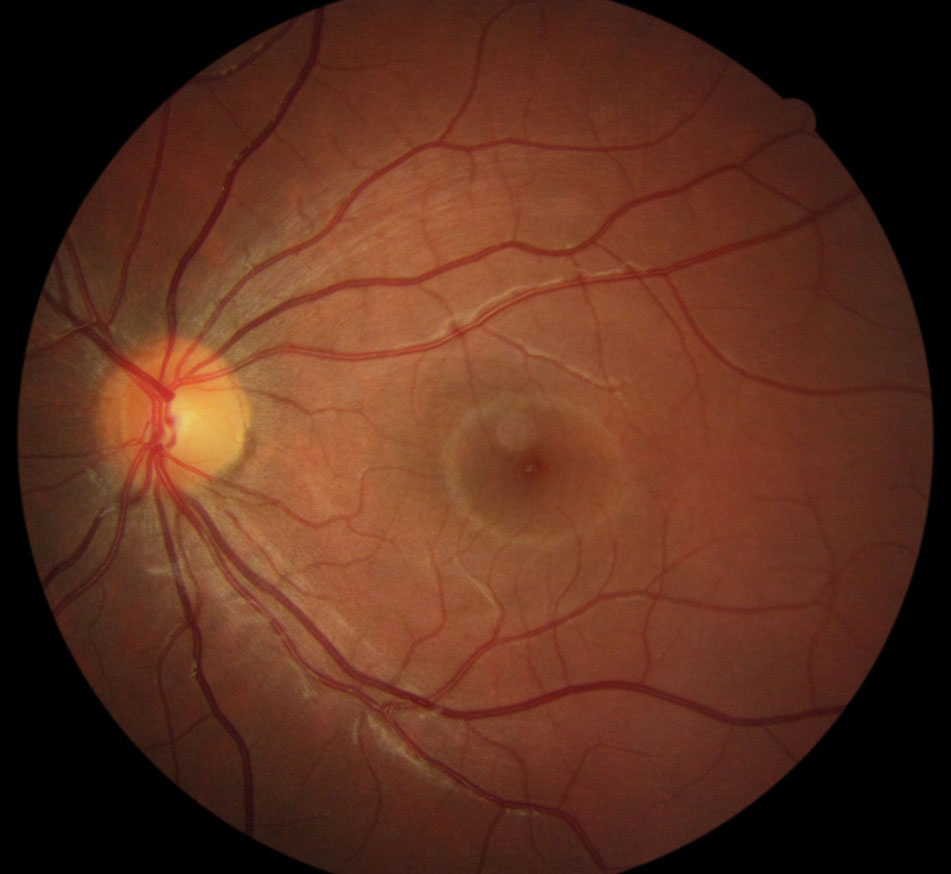

(951, 874)


In [31]:
from PIL import Image
img_path = ROOT / "data" / "brset" / "images" / 'img00042.jpg'
img = Image.open(img_path)
print(img.size)
display(img)

In [22]:
from pathlib import Path
import io

import h5py
import numpy as np
from PIL import Image
from tqdm import tqdm


def image_to_jpeg_uint8(image_path, size=(256, 256), quality=95):
    with Image.open(image_path) as img:
        img = img.convert("RGB")
        img = img.resize(size, Image.Resampling.LANCZOS)

        buffer = io.BytesIO()
        img.save(buffer, format="JPEG", quality=quality)

        return np.frombuffer(buffer.getvalue(), dtype=np.uint8)


def create_hdf5_from_metadata(df, image_dir, out_filepath, id_col="image_id", size=(256, 256)):
    image_dir = Path(image_dir)
    out_filepath = Path(out_filepath)
    out_filepath.parent.mkdir(parents=True, exist_ok=True)

    with h5py.File(out_filepath, "w") as h5:
        h5.attrs["format"] = "jpeg_uint8_bytes"
        h5.attrs["image_size"] = str(size)
        h5.attrs["id_col"] = id_col

        for image_id in tqdm(df[id_col].astype(str), desc=f"Creating {out_filepath.name}"):
            image_path = image_dir / f"{image_id}.jpg"

            if not image_path.exists():
                raise FileNotFoundError(f"Missing image: {image_path}")

            jpeg_arr = image_to_jpeg_uint8(image_path, size=size)
            h5.create_dataset(image_id, data=jpeg_arr, dtype=np.uint8)

    print(f"Created: {out_filepath}")

In [35]:
# load csv
image_dir = ROOT / "data" / "brset" / "images"
processed_dir = ROOT / "data" / "brset" / "processed"

train_metadata_path = processed_dir / "train-metadata.parquet"
test_metadata_path = processed_dir / "test-metadata.parquet"

train_df = pd.read_parquet(train_metadata_path)
test_df = pd.read_parquet(test_metadata_path)

In [23]:
create_hdf5_from_metadata(
    df=train_df,
    image_dir=image_dir,
    out_filepath=processed_dir / "train-image.hdf5",
    id_col="image_id",
    size=(512, 512),
)

create_hdf5_from_metadata(
    df=test_df,
    image_dir=image_dir,
    out_filepath=processed_dir / "test-image.hdf5",
    id_col="image_id",
    size=(512, 512),
)

Creating train-image.hdf5: 100%|██████████| 13012/13012 [43:08<00:00,  5.03it/s] 


Created: /Users/cgiovannoni/PycharmProjects/isic24-dum/data/brazilian/processed/train-image.hdf5


Creating test-image.hdf5: 100%|██████████| 3254/3254 [10:57<00:00,  4.95it/s] 


Created: /Users/cgiovannoni/PycharmProjects/isic24-dum/data/brazilian/processed/test-image.hdf5


(512, 512)


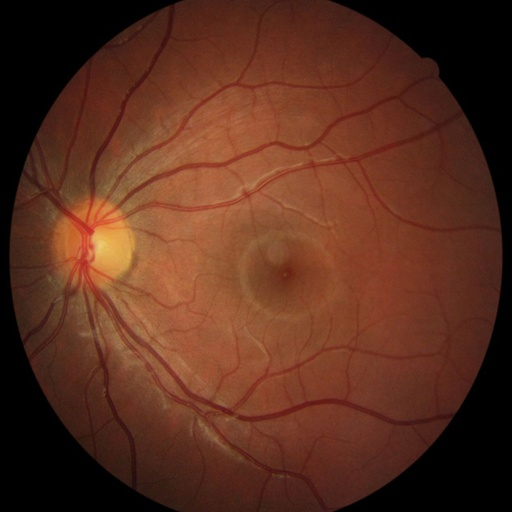

In [39]:
#sanity-check
image_id = "img00042"

with h5py.File(processed_dir / "train-image.hdf5", "r") as h5:
    file_bytes = h5[image_id][()].tobytes()

img = Image.open(io.BytesIO(file_bytes)).convert("RGB")
print(img.size)
display(img)